# Learning a function from derivatives

Suppose we can measure a function's slope and curvature, but not its value.

We'll combine the two kinds of derivative readings, predict function values
and changes between locations, then add a single value measurement. That one
reading will reduce uncertainty across the whole interval.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp

from gpex import (
    FunctionalBlock, FunctionalDataset, FunctionalQuery,
    GaussianProcess, ObservationBlock, kernels, operators,
)

In [2]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})
BLUE, PURPLE, ORANGE = "#1F4E79", "#6D597A", "#D97706"


def plot_prediction(ax, locations, prediction, name, label, color):
    mean = prediction.mean[name]
    sd = jnp.sqrt(prediction.variance[name])
    ax.plot(locations[:, 0], mean, color=color, lw=2, zorder=3, label=label)
    ax.fill_between(
        locations[:, 0], mean - 1.96 * sd, mean + 1.96 * sd,
        color=color, alpha=0.12, zorder=0,
    )


def plot_draws(ax, locations, draws, name, color):
    ax.plot(
        locations[:, 0], draws[name].T,
        color=color, lw=0.8, alpha=0.3, zorder=1,
    )

## Observe slopes and curvature

Use a known function to generate a small dataset. We take six noisy slope
readings and three noisy curvature readings at different locations. The errors
are independent Gaussians with standard deviations `0.08` and `0.15`.

`PartialDerivative(axis=0)` measures $f'(x)$. In one dimension, `Laplacian()`
measures $f''(x)$. An operator's `apply` method lets us generate the corresponding
synthetic reading from our known function.

In [3]:
def truth(point):
    x = point[0]
    return 1.2 + jnp.sin(1.8 * x) + 0.15 * x


slope = operators.PartialDerivative(axis=0)
curvature = operators.Laplacian()

x_slope = jnp.array([[-1.35], [-0.9], [-0.35], [0.15], [0.8], [1.3]])
x_curvature = jnp.array([[-1.1], [0.45], [1.05]])

y_slope = jax.vmap(lambda point: slope.apply(truth, point))(x_slope)
y_slope += 0.08 * jax.random.normal(jax.random.key(2), (6,))
y_curvature = jax.vmap(lambda point: curvature.apply(truth, point))(x_curvature)
y_curvature += 0.15 * jax.random.normal(jax.random.key(3), (3,))

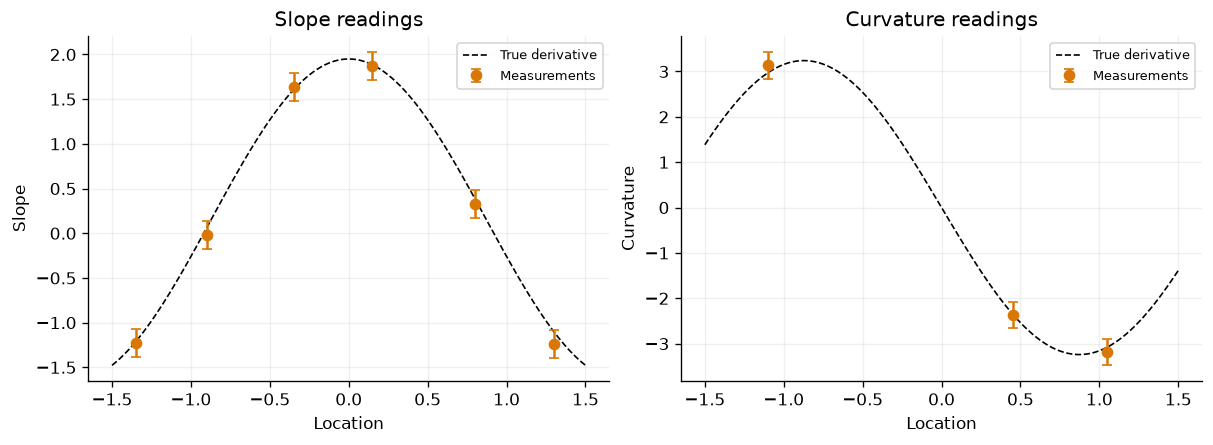

In [4]:
x_plot = jnp.linspace(-1.5, 1.5, 121)[:, None]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for ax, locations, readings, operator, sd, title in [
    (axes[0], x_slope, y_slope, slope, 0.08, "Slope readings"),
    (axes[1], x_curvature, y_curvature, curvature, 0.15, "Curvature readings"),
]:
    reference = jax.vmap(lambda point: operator.apply(truth, point))(x_plot)
    ax.plot(x_plot[:, 0], reference, "k--", lw=1, label="True derivative")
    ax.errorbar(
        locations[:, 0], readings, yerr=1.96 * sd,
        fmt="o", color=ORANGE, capsize=3, label="Measurements",
    )
    ax.set(title=title, xlabel="Location", ylabel=title.split()[0])
    ax.legend(fontsize=8)
plt.show()

The orange readings lie close to the true derivatives shown by the dashed
lines. The error bars show the measurement-error scale, extending `1.96`
standard deviations in each direction.

## Infer the function from the derivative readings

Put each sensor type in its own observation block, with its operator and
measurement-error variance. Each fixed block reserves just enough space for
its readings.

In [5]:
slope_block = ObservationBlock.from_arrays(
    x_slope, y_slope, operator=slope,
    variance=0.08**2, name="slopes", max_size=6,
)
curvature_block = ObservationBlock.from_arrays(
    x_curvature, y_curvature, operator=curvature,
    variance=0.15**2, name="curvatures", max_size=3,
)
derivative_data = FunctionalDataset([slope_block, curvature_block])

The RBF prior describes smooth functions, so both derivative types are
well defined. Its lengthscale of `1.0` lets the nearby derivative measurements
inform the shape between them.

In [6]:
gp = GaussianProcess(kernels.RBFKernel(variance=4.0, lengthscale=1.0))
from_derivatives = gp.condition(derivative_data)

We want the function itself and its change over a distance of `0.4`.
Use `Identity()` for $f(x)$ and `Increment([0.4])` for $f(x+0.4)-f(x)$.
The increment is a difference of values, without dividing by the distance.

Both query operators differ from the observation operators. The block names
let us retrieve each prediction from the result.

In [7]:
x_change = jnp.linspace(-1.5, 1.1, 105)[:, None]
change = operators.Increment(jnp.array([0.4]))
query = FunctionalQuery([
    FunctionalBlock(x_plot, operators.Identity(), name="function"),
    FunctionalBlock(x_change, change, name="change"),
])
before = from_derivatives.predict_marginals(query)
before_draws = from_derivatives.sample(jax.random.key(10), query, sample_count=10)

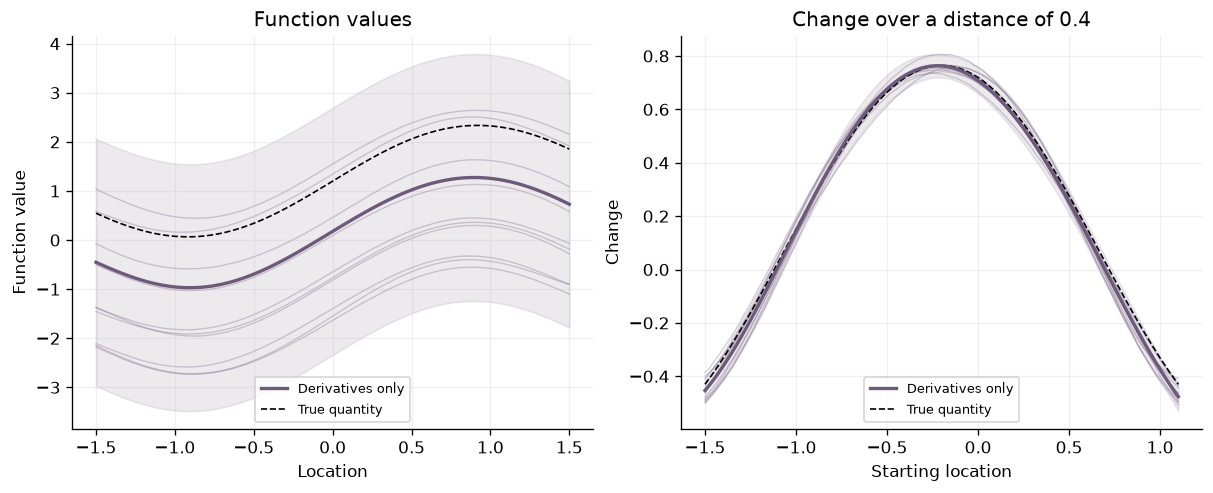

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, locations, operator, name, title, ylabel in [
    (axes[0], x_plot, operators.Identity(), "function", "Function values", "Function value"),
    (axes[1], x_change, change, "change", "Change over a distance of 0.4", "Change"),
]:
    plot_draws(ax, locations, before_draws, name, PURPLE)
    plot_prediction(ax, locations, before, name, "Derivatives only", PURPLE)
    reference = jax.vmap(lambda point: operator.apply(truth, point))(locations)
    ax.plot(locations[:, 0], reference, "k--", lw=1, label="True quantity")
    ax.set(title=title, xlabel="Location", ylabel=ylabel)
    ax.legend(fontsize=8, loc="lower center")
axes[1].set_xlabel("Starting location")
function_limits = axes[0].get_ylim()
plt.show()

The faint lines show ten posterior draws. The functions have similar shapes
but different levels, while their increments agree closely. Shaded bands show
pointwise 95% posterior intervals.

Adding a constant changes neither slope nor curvature: these readings cannot
distinguish $f(x)$ from $f(x)+c$. The GP prior still expresses a preference for
that level, but the derivative measurements cannot determine it.

## Add one value to locate the function's level

A single value measurement anchors the function. Here we measure it at `-0.2`,
with measurement-error standard deviation `0.05`, and combine all three blocks.

In [9]:
x_value = jnp.array([[-0.2]])
y_value = jax.vmap(truth)(x_value)
y_value += 0.05 * jax.random.normal(jax.random.key(4), (1,))

value_block = ObservationBlock.from_arrays(
    x_value, y_value, operator=operators.Identity(),
    variance=0.05**2, name="value", max_size=1,
)
with_value = gp.condition(
    FunctionalDataset([slope_block, curvature_block, value_block])
)
after = with_value.predict_marginals(query)
after_draws = with_value.sample(jax.random.key(11), query, sample_count=10)

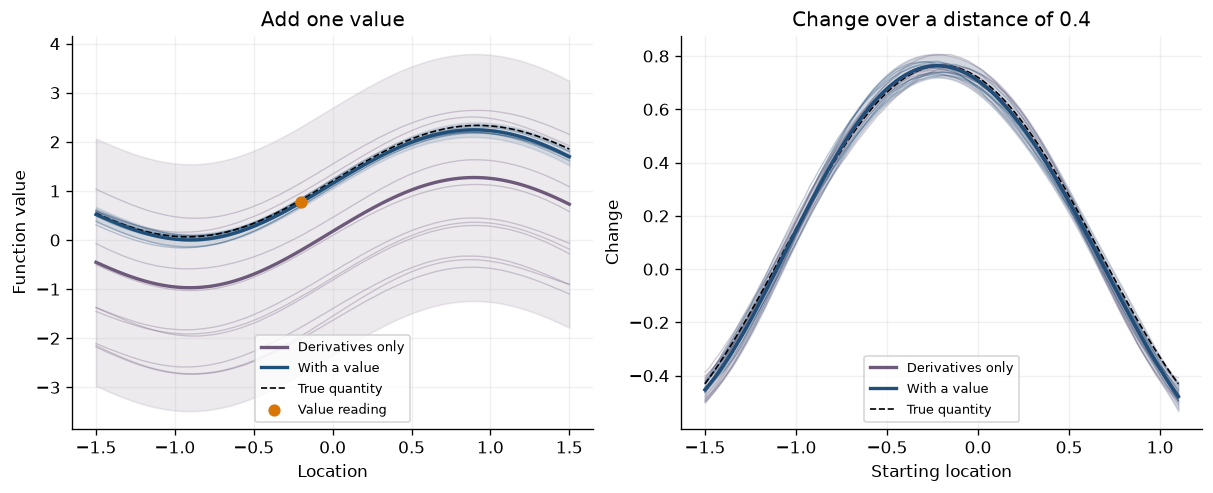

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for ax, locations, operator, name, title, ylabel in [
    (axes[0], x_plot, operators.Identity(), "function", "Add one value", "Function value"),
    (axes[1], x_change, change, "change", "Change over a distance of 0.4", "Change"),
]:
    plot_draws(ax, locations, before_draws, name, PURPLE)
    plot_draws(ax, locations, after_draws, name, BLUE)
    plot_prediction(ax, locations, before, name, "Derivatives only", PURPLE)
    plot_prediction(ax, locations, after, name, "With a value", BLUE)
    reference = jax.vmap(lambda point: operator.apply(truth, point))(locations)
    ax.plot(locations[:, 0], reference, "k--", lw=1, label="True quantity")
    ax.set(title=title, xlabel="Location", ylabel=ylabel)
axes[0].scatter(
    x_value[:, 0], y_value, color=ORANGE, s=40, zorder=4, label="Value reading"
)
axes[0].set_ylim(function_limits)
axes[1].set_xlabel("Starting location")
for ax in axes:
    ax.legend(fontsize=8, loc="lower center")
plt.show()

The blue draws now agree much more closely on the function's level. One value measurement tightens the prediction across the
interval covered by the derivative readings, including far from the measured
value. The increment prediction barely changes: an additive constant cancels
in $f(x+0.4)-f(x)$.

The next tutorial, [Learning from averages](nonlocal-measurements.ipynb),
explores a different ambiguity: measurements over a window can leave variation
inside that window unresolved.